# Monkey Finger Movement Dataset

## 1. Overview

The following dataset includes data from two recording sessions of a macque performing a two degree-of-freedom (DOF) finger movement task, with neural activity recorded from the hand area of the primary motor cortex. The data is publicly available and can be downloaded at [this link](https://deepblue.lib.umich.edu/data/concern/data_sets/fj236353v). This dataset is a modified version of [another dataset](https://deepblue.lib.umich.edu/data/concern/data_sets/0g354f51t). Specifically, the dataset presented here is a modified version of Data.zip/MonkeyN_CO.mat and Data.zip/MonkeyN_R.mat. The full, unmodified dataset was used to generate many of the results presented in the [Nason, S. R. et al. 2021 study](https://doi.org/10.1016/j.neuron.2021.08.009), "Real-time linear prediction of simultaneous and independent movements of two finger groups using an intracortical brain-machine interface", published in Neuron.

Both datasets are also accessible through the Chestek Lab website [here](https://chestekresearch.engin.umich.edu/data-and-resources/). Before using this notebook, download the datasets and make sure they are included in your workspace. Create a 'Datasets' Folder in the root of this repo and copy the .pkl files into there.

**NOTE FOR ORGANIZERS (DELETE BEFORE RUNNING WORKSHOP)**
If you are going to use Google Colab to run this workshop, download the dataset and upload it to a google drive so you can use gdown, probably easier than having each student download and upload it manually. Or if there's a shared workspace, just put all the files there first.


<img src="https://raw.githubusercontent.com/chesteklab/EFRI-workshop-2023/main/Notebooks/img/methods.png" alt="drawing" width="600"/>

### 1.1 Task

In the finger movement task, a rhesus macaque (Monkey N) performed successive 'trials' where he had to independently move his index finger (IDX) and middle-ring-pinky fingers (MRP) to match target positions within a set time limit. The targets were shown using a monitor placed in front of him, as shown above, which displayed a virtual hand and two spherical targets (red for IDX, yellow for MRP). Once the monkey reached the targets, he had to hold his fingers in place for a set 'hold time' to complete the the trial successfully. After each successful trial, the monkey received a juice reward.

The datasets provided here consist of two different 'target styles', center-out and random targets. In the center-out task, trials alternate between 'rest' trials and 'reach' trials. Rest trials present both targets at halfway between flexion and extension, while reach trials involve some kinda of movement away from rest - split movements in different directions, both fingers flexing/extending, and single group flexion/extension. In the random task, targets are presented pseudo-randomly for both finger groups, although a limit is imposed on how far finger groups can be separated from one another. Datasets from the center-out and random tasks are labelled 'co_feats##.pkl' and 'r_feats##.pkl', respectively.

### 1.2 Data

For these datasets, 96 channels of neural activity were recorded from a Utah array implanted in the hand area of a monkey's motor cortex during the task. The neural feature used in these datasets is Spiking-Band Power (SBP), as described by Nason et al. 2020 in Nature Biomedical engineering ([link](https://doi.org/10.1038/s41551-020-0591-0)).

Additionally, relative finger position along the arc of flexion/extension was measured using a flex sensors in the manipulandum where the monkeys hand was placed. We estimated the finger group velocities and accelerations using the recorded hand positions.

The random and center-out trials provided are each two sets of experiments combined into one (four experiments combined into two total). All trials were collected on the same day, but other tasks were performed in between. In the center-out dataset, trial 752 marks the start of the second block, and in the random dataset, trial 497 marks the start of the second block. In both datasets, some trials are excluded, likely due to trial failure.

Neural data was originally recorded at 2ksps, and behavior was recorded at 1ksps. However, decoding is typically done on larger time bins. The datasets provided all contain the same data binned at different sizes, 10ms, 20ms, 32ms, 50ms, and 100ms, indicated by the number in the filename. For example, 'r_feats32.pkl' contains the random task data binned at 32ms, and 'r_feats50.pkl' contains the same data binned at 50ms.

## 2. Exploring the data

### 2.1 Setup

First, let's load one of the datasets and import things we may need. For this example, we will used the 32ms center-out dataset.

In [23]:
#### OPTIONAL GDOWN IF YOU DOWNLOAD AND REUPLOAD THE DATA TO A GOOGLE DRIVE FOLDER
# # if in google colab install
# !gdown --folder https://drive.google.com/drive/folders/<INSERT GOOGLE DRIVE LINK HERE>
# !pip install -q ipympl

In [1]:
# imports
import pickle
import os
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
from ipywidgets import *

from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

In [3]:
from ipywidgets import interact

@interact(x=(0, 100, 1), greeting=["Hello", "Hi", "Hey"])
def preview_function(x=50, greeting="Hello"):
    print(f"{greeting}! The slider value is: {x}")

interactive(children=(IntSlider(value=50, description='x'), Dropdown(description='greeting', options=('Hello',…

In [4]:
# if cloning repo and running on jupyter, only need to run this cell
# load dataset using pickle
# datapath = os.path.join('</FILE/PATH/TO/DATASET/FOLDER>/co_feats32.pkl') # run this line if in jupyter/cloned repo
datapath = os.path.join('C:\\Repos\\neural-decoding-workshop\\Datasets\\co_feats32.pkl')
# datapath = os.path.join(os.getcwd(),'Monkey_Datasets', 'co_feats32.pkl') # run this line if colab
with open(datapath, 'rb') as f:
    data = pickle.load(f)

### 2.2 Data Structure

Each .pkl file contains a dictionary of 5 length N numpy.ndarrays, where N is the total number of time bins in the dataset. The keys and their contents are listed below:

* `'neural'` - Nx96 numpy.ndarray containing the binned (average) SBP for all 96 channels.
* `'behavior'` - Nx6 ndarray containing finger kinematics in the following order: `[IDX_position, MRP_position, IDX_velocity, MRP_velocity, IDX_accel, MRP_accel]`
* `'trialNumber'` - Nx1 ndarray containing the current trial number.
* `'targetPosition'` - Nx2 ndarray containing the target position for both finger groups (`[IDX_target, MRP_target]`).
* `'targetWidth'` - Nx1 ndarray containing the target width.

In [5]:
# quick lil dataframe to make it visual
dfs = []
for key in data.keys():
    dfs.append(pd.DataFrame(data[key]))
dfs = pd.concat(dfs, axis=1, keys=data.keys())
dfs

neural                                                       \
               0          1          2          3         4         5   
0       9.156250   9.265625  11.515625  10.671875  6.500000  6.968750   
1       8.876923   9.169231  13.153846   8.661538  5.707692  7.338462   
2      10.609375  11.593750  10.453125  11.937500  6.640625  7.281250   
3       9.937500   8.750000  10.250000  11.468750  6.046875  5.515625   
4      10.687500   9.390625  13.296875  12.171875  7.031250  6.343750   
...          ...        ...        ...        ...       ...       ...   
58922  13.765625  13.859375  16.625000  15.125000  7.015625  7.312500   
58923  14.218750  10.468750  18.312500  12.953125  7.609375  7.140625   
58924  16.015625  10.765625  19.640625  13.421875  6.843750  7.593750   
58925  12.184615  10.753846  15.507692  12.230769  6.600000  7.246154   
58926  13.578125  11.875000  17.921875  11.203125  7.093750  7.078125   

                                                   ...  behavior            \
               6          7          8          9  ...         0         1   
0      10.078125   8.453125   8.062500   8.109375  ...  0.538462  0.590020   
1      16.492308   9.384615   8.200000   7.061538  ...  0.538341  0.590323   
2      13.921875   7.640625   8.062500   6.890625  ...  0.537981  0.590323   
3      11.406250   8.218750   8.937500   8.375000  ...  0.537981  0.589919   
4      13.000000   8.953125   8.375000   8.218750  ...  0.538822  0.590423   
...          ...        ...        ...        ...  ...       ...       ...   
58922  17.984375   9.281250  10.906250   9.421875  ...  0.593149  0.639214   
58923  15.046875  11.875000  12.156250   7.875000  ...  0.578245  0.662802   
58924  12.625000  11.906250  10.265625   9.515625  ...  0.546034  0.734375   
58925  17.076923  10.030769   9.646154  10.061538  ...  0.550601  0.759980   
58926  11.718750   8.750000  10.828125   9.609375  ...  0.547716  0.753730   

                                              trialNumber targetPosition       \
              2         3         4         5           0              0    1   
0     -0.000120  0.000302 -0.000240 -0.000302           1            0.5  0.5   
1     -0.000361  0.000000  0.000361 -0.000403           1            0.5  0.5   
2      0.000000 -0.000403  0.000841  0.000907           1            0.5  0.5   
3      0.000841  0.000504 -0.001442 -0.000504           1            0.5  0.5   
4     -0.000601  0.000000  0.001442  0.000202           1            0.5  0.5   
...         ...       ...       ...       ...         ...            ...  ...   
58922 -0.014904  0.023589 -0.017308  0.047984        1530            0.5  0.8   
58923 -0.032212  0.071573  0.036779 -0.045968        1530            0.5  0.8   
58924  0.004567  0.025605 -0.007452 -0.031854        1530            0.5  0.8   
58925 -0.002885 -0.006250  0.000000  0.000000        1530            0.5  0.8   
58926  0.000000  0.000000  0.000000  0.000000        1530            0.5  0.8   

      targetWidth  
                0  
0           0.075  
1           0.075  
2           0.075  
3           0.075  
4           0.075  
...           ...  
58922       0.075  
58923       0.075  
58924       0.075  
58925       0.075  
58926       0.075  

[58927 rows x 106 columns]

### 2.3 Visualizing movements

To visualize the movements, we can use the following function to plot each DOF of behavior on a separate axis. This function will also plot the targets as rectangles. The height of the rectangle represents the 'target' zone that the DOF needs to move into for a trial to be successful.

In [6]:
def plottrials(data, finger, starttrial, numtrials, ax):
    """
    Plots the behavior of a given finger group for a specified number of trials, starting from a specified trial number. 
    The function also highlights the target positions and widths for each trial.

    Keyword arguments:
    data -- the dataset containing trial information and behavior data
    finger -- the index of the finger group to plot (0 for index, 1 for middle-ring-pinky)
    starttrial -- the trial number to start plotting from
    numtrials -- the number of trials to plot
    ax -- the matplotlib axis to plot on
    """

    # get list of trials, first index of each, and length of each
    trials, tidx, tlens = np.unique(data['trialNumber'], return_index=True, return_counts=True)
    startidx = int(np.argwhere(trials == starttrial)[0][0])
    startbin = tidx[startidx]
    endbin = tidx[startidx+numtrials]
    #get target location and width for each trial
    targets = data['targetPosition'][tidx,:]
    twidths = data['targetWidth'][tidx,:]

    for i in np.arange(startidx,startidx+numtrials):
        rect = mpl.patches.Rectangle((tidx[i], targets[i,finger] - twidths[i,0]),tlens[i], twidths[i,0]*2, alpha=0.3)
        ax.add_patch(rect)

    ax.plot(data['behavior'][:,finger])
    ax.set(xlim=(startbin, endbin))

Let's plot the first 10 trials of the dataset (the first trial is a dud):

[Text(0.5, 0, 'Time (bins)'), Text(0, 0.5, 'Finger Position (0-1)')]

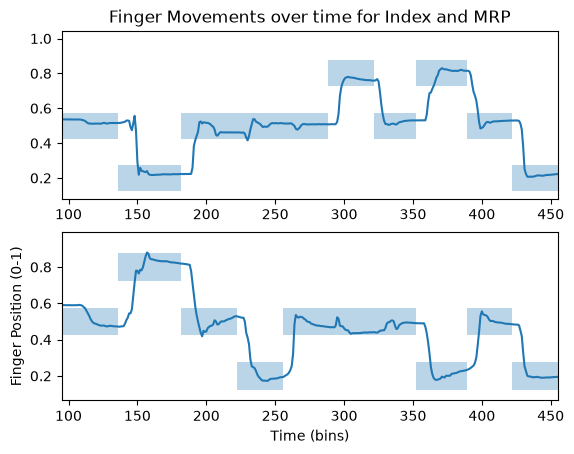

In [7]:
fig, ax = plt.subplots(2,1)

plottrials(data, 0, 2, 10, ax[0])
plottrials(data, 1, 2, 10, ax[1])

ax[0].set_title('Finger Movements over time for Index and MRP')
ax[1].set(xlabel='Time (bins)', ylabel='Finger Position (0-1)')

The top plot shows the index position and targets for the first 10 trials, and the bottom shows the same for MRP. Another common way to look at behavior data is to plot it in a 2D plane, with the x and y axes representing the positions of each finger group. You can also create either plot with velocities, though targets can't be included on those.

### 2.4 Single-neuron responses

Something we might be interested in looking at is how individual neurons respond to specific movements. This is relatively simple to look at when using a center-out task, where the same movements are repeated over and over. Below, we group all movements of the same type and look at how individual neurons respond.

In [16]:
# group center out movements and show average trajectory, as well as corresponding neural data?
reachpositions = np.unique(data['targetPosition'], axis=0)
grouped = {'neural':[], 'behavior':[]}
for position in reachpositions:
    #get all trials for this target positions
    trials = np.unique(data['trialNumber'][np.argwhere((data['targetPosition'] == position).all(axis=1))])

    lens = np.stack([np.sum(data['trialNumber'] == trial) for trial in trials])

    # we need to align our trials since they are usually different lengths.
    # There are better ways to do this (time warping, etc.), but here we'll just truncate to the shortest trial of the group
    behavior = np.zeros((len(lens), np.min(lens), 6))
    neural = np.zeros((len(lens), np.min(lens), 96))
    for i, trial in enumerate(trials):
        behavior[i,:,:] = data['behavior'][(data['trialNumber'] == trial)[:,0],:][0:np.min(lens),:]
        neural[i,:,:] = data['neural'][(data['trialNumber'] == trial)[:,0],:][0:np.min(lens),:]

    grouped['behavior'].append(behavior)
    grouped['neural'].append(neural)

def plotSingleNeuronResponses(channel = 0):
    fig, ax = plt.subplots(1,2, figsize=(9,4))

    for i, position in enumerate(reachpositions):
        mean_behavior = np.mean(grouped['behavior'][i], axis=0)
        mean_neural = np.mean(grouped['neural'][i], axis=0)
        ax[0].plot(mean_behavior[:,0],mean_behavior[:,1],label=str(position))
        ax[1].plot(mean_neural[:,channel])

    ax[0].set(title='Average Movement Trajectory',xlabel='Index Position',ylabel='MRP Position')
    ax[1].set(ylabel='Average SBP',xlabel='Time (binsize)',title=f'Channel {channel}')
    plt.show()

In [ ]:
interactive_plot = interactive(plotSingleNeuronResponses, channel = IntSlider(min=0,max=95,step=1))
interactive_plot

interactive(children=(IntSlider(value=0, description='channel', max=95), Output()), _dom_classes=('widget-inte…

In the above plots: On the left, you can see the average trajectory for each movement type. In the right plot, you can see the average response by movement type for a single neuron. Using the slider above the plots, you can change which channel is shown on the plot, it is a bit slow due so give it a second to update. Poke around and see if you can spot any noticeable changes in response!

### 2.5 Decoding Finger Kinematics

Next, we'll try to decode the monkey's finger velocities using the neural data. We'll use a ridge regression, an regularized version of linear regression. Additionally, we'll add some time history, basically appending columns to the neural data with the data shifted, to give the decoder the ability to look back. Since there's typically some lag between when movements are represented in the brain and when they're actually performed, this should improve our decode.

**Linear/Ridge Regression:** A mapping of a similar form to an equation you might be familiar with `y = mx+b`. Here, your `x` is neural data, and your `y` is one of the degrees of freedom you are predicting, so in reality it looks more like `y = m\*x_1 + m\*x_2 + ... + m\*x_96 + b`.

**Time History:** Looking at past neural data can improve decoding performance, so we shift our neural data by 1 time bin at a time (up to however much time history we want to add) and concatenate those features to our existing neural data. That way, a decoder can predict movement using current and past neural data.

In [18]:
# get neural data and hand velocities
neu = data['neural']
vel = data['behavior'][:,[2,3]]

# adding time history
hist = 6
adjneu = np.zeros((neu.shape[0]-hist, 96, hist+1))
for h in range(hist+1):
    adjneu[:,:,h] = neu[h:neu.shape[0]-hist+h,:]
adjneu = adjneu.reshape(adjneu.shape[0],-1)
adjvel = vel[hist:,:]

# separate a training and test set
X_train, X_test, y_train, y_test = train_test_split(adjneu, adjvel, test_size=0.2, shuffle=False)

# train a ridge regression
ridge = Ridge(alpha=0.001)
ridge.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga

Now, our model is trained, and we can test it. We measure performance here using the coefficient of determination, also known as R-squared.

In [19]:
# test the ridge regression
yhat = ridge.predict(X_test)

# show test r^2
print(f'Test R2: {ridge.score(X_test, y_test)}')

Test R2: 0.32049903164209004


Next, we can plot these predictions and visually compare them to ground truth test data:

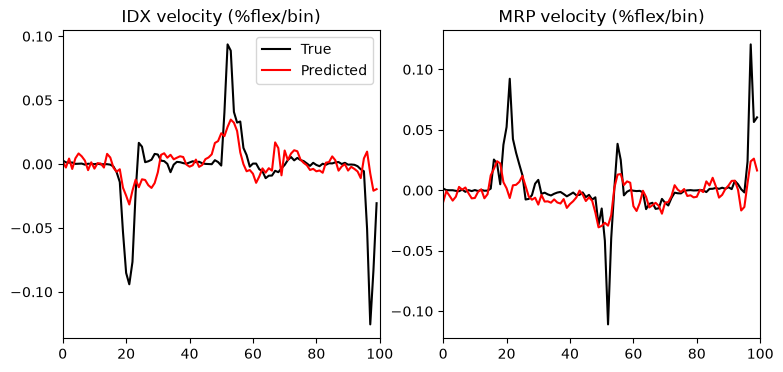

In [20]:
# plot predicted vs. true kinematics

fig, ax = plt.subplots(1,2, figsize = (9, 4))
finger = ['IDX','MRP']
for i in range(2):
    ax[i].plot(y_test[0:100,i], c='k')
    ax[i].plot(yhat[0:100,i], c='r')
    ax[i].set(xlim=(0,100),title=f'{finger[i]} velocity (%flex/bin)')
    if i == 0:
        ax[i].legend(('True', 'Predicted'))

### 2.6 Neural Trajectories

Instead of single-neuron responses, we could have a look at how the neural activity changes with different movements at a population level. To do this, we can use a dimensionality reduction technique like principal component analysis (PCA) to see how our the activity changes at a higher level in a 'latent space'.

For those unfamiliar, PCA calculates new axes for a dataset which, in order, account for the largest variance in the data overall. In our case, this means PCA gives us a transform which shifts our data from a space where each dimension represents a neural channel to a space where each dimension accounts for a progressively smaller amount of the variance in neural data. These new dimensions are called the principal components (PCs), and can be used to i) look at how a high-dimensional dataset changes at a population level, and ii) as a dimensionality reduction tool, where you apply PCA to a large dataset and then only take only the top few PCs which account for most of the variance.

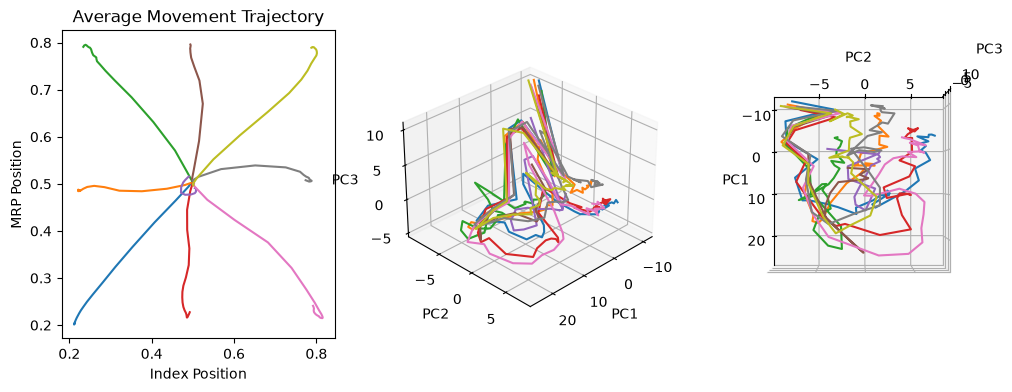

[0.24812291 0.10394717 0.08925182]


In [22]:
# run pca on our neural data
pca = PCA()
neural_pca = pca.fit_transform(data['neural'])

#lets group these by positions and average, like before:
reachpositions = np.unique(data['targetPosition'], axis=0)

fig = plt.figure(figsize=(12,4))

ax1 = fig.add_subplot(1,3,1)
ax2 = fig.add_subplot(1,3,2, projection='3d')
ax3 = fig.add_subplot(1,3,3, projection='3d')
ax = [ax1,ax2, ax3]

grouped = {'neural_pca':[], 'behavior':[]}
for position in reachpositions:
    #get all trials for this target positions
    trials = np.unique(data['trialNumber'][np.argwhere((data['targetPosition'] == position).all(axis=1))])

    lens = np.stack([np.sum(data['trialNumber'] == trial) for trial in trials])

    # we need to align our trials since they are usually different lengths.
    # There are better ways to do this (time warping, etc.), but here we'll just truncate to the shortest trial of the group
    behavior = np.zeros((len(lens), np.min(lens), 6))
    neural = np.zeros((len(lens), np.min(lens), 96))
    for i, trial in enumerate(trials):
        behavior[i,:,:] = data['behavior'][(data['trialNumber'] == trial)[:,0],:][0:np.min(lens),:]
        neural[i,:,:] = neural_pca[(data['trialNumber'] == trial)[:,0],:][0:np.min(lens),:]

    grouped['behavior'].append(behavior)
    grouped['neural_pca'].append(neural)

    mean_behavior = np.mean(behavior, axis=0)
    mean_neural = np.mean(neural, axis=0)

    ax[0].plot(mean_behavior[:,0],mean_behavior[:,1],label=str(position))
    ax[1].view_init(elev=30, azim=45)
    ax[1].plot(mean_neural[:,0], mean_neural[:,1],mean_neural[:,2])
    ax[1].set(xlabel='PC1',ylabel='PC2',zlabel='PC3')
    ax[2].view_init(elev=90, azim=0)
    ax[2].plot(mean_neural[:,0], mean_neural[:,1],mean_neural[:,2])
    ax[2].set(xlabel='PC1',ylabel='PC2',zlabel='PC3')

ax[0].set(title='Average Movement Trajectory',xlabel='Index Position',ylabel='MRP Position')
plt.show()
print(pca.explained_variance_ratio_[0:3])

Similarly to Section 2.4, the plot on the left shows the average trajectory for each kind of movement in the center-out task. On the right, we can see a 3-D plot showing the average trajectory of the first 3 principal components for each movement.

By selecting the first few PC's, we can look at how the neural data changes as a population over time, rather than looking at each channel individually. As you examine these 'neural trajectories' note the similarities, the rotation-like movement through the lower-dimensional subspace of these first the principal components, but also, note the differences.

Below the plots, we've printed the variance in the data explained by each of the top 3 principal components. Combined, they account for less than 50% of the variance in our neural data, so there is likely still valuable information about the neural population (and potentially about the task) not shown here.

### Summary

In this notebook, we:
- introduced the Monkey finger movement dataset, describing the taks and provided data
- looked at how the data is setup
- demonstrated the task by plotting example movements
- explored single-neuron responses by plotting average SBP for center-out movements
- evaluated how SBP population activity can decode finger velocities
- visualized the timecourse of the neural population activity by extracting trial-averaged neural trajectories with PCA